# Data Science Jobs - Salary Classification
Predict if a job has a High or Low salary (compared to the median).

In [1]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

import warnings
warnings.filterwarnings('ignore')

## Task 1: Data Exploration

In [2]:
df = pd.read_csv('jobs_dataset.csv')
df.head(3)

,company,rating,location,positionName,description,salary,url,jobType/0,jobType/1,jobType/2,jobType/3,searchInput/country,searchInput/position,externalApplyLink
0,Google,4.3,"San Bruno, CA","Senior Data Scientist, Research, YouTube Search",Note: By applying to this position you will ha...,"$166,000 - $244,000 a year",https://www.indeed.com/viewjob?jk=3129ec5dde24...,Full-time,NaN,NaN,NaN,US,Data Scientist,https://www.google.com/about/careers/applicati...
1,BAXTER,3.7,"Milwaukee, WI 53214",Senior AI Engineer - Data Scientist,This is where you save and sustain lives\n\nAt...,"$112,000 - $154,000 a year",https://www.indeed.com/viewjob?jk=19da1b85455c...,Full-time,NaN,NaN,NaN,US,Data Scientist,https://jobs.baxter.com/en/job/-/-/152/8298788...
2,Meta,4.2,"Redmond, WA","Audio Software Engineer, Applied Scientist","Redmond, WA • + 2 more•Full Time\nMessenger\nM...",$70.67 an hour,https://www.indeed.com/viewjob?jk=0b0b432e2a51...,Full-time,NaN,NaN,NaN,US,Data Scientist,https://www.metacareers.com/jobs/3101204833367...


In [3]:
print('Shape:', df.shape)
print()
df.info()

Shape: (735, 14)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 735 entries, 0 to 734
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   company               735 non-null    object 
 1   rating                735 non-null    float64
 2   location              735 non-null    object 
 3   positionName          735 non-null    object 
 4   description           735 non-null    object 
 5   salary                506 non-null    object 
 6   url                   735 non-null    object 
 7   jobType/0             501 non-null    object 
 8   jobType/1             19 non-null     object 
 9   jobType/2             1 non-null      object 
 10  jobType/3             1 non-null      object 
 11  searchInput/country   735 non-null    object 
 12  searchInput/position  735 non-null    object 
 13  externalApplyLink     553 non-null    object 
dtypes: float64(1), object(13)
memory usage: 80.5+ KB


In [4]:
print('Missing values per column:')
print(df.isnull().sum())
print()
print('Duplicated rows:', df.duplicated().sum())

Missing values per column:
company                   0
rating                    0
location                  0
positionName              0
description               0
salary                  229
url                       0
jobType/0               234
jobType/1               716
jobType/2               734
jobType/3               734
searchInput/country       0
searchInput/position      0
externalApplyLink       182
dtype: int64

Duplicated rows: 0


In [5]:
print(df['rating'].describe())
print()
print('Job types:')
print(df['jobType/0'].value_counts(dropna=False))
print()
print('Top companies:')
print(df['company'].value_counts().head(8))

count    735.000000
mean       3.232109
std        1.357551
min        0.000000
25%        3.300000
50%        3.700000
75%        4.000000
max        5.000000
Name: rating, dtype: float64

Job types:
jobType/0
Full-time     439
NaN           234
Contract       42
Part-time      10
Temporary       5
Internship      4
Permanent       1
Name: count, dtype: int64

Top companies:
company
Amazon                     24
Apple                      20
Meta                       20
Amazon.com Services LLC    15
Google                     14
Handshake                  12
Wells Fargo                10
JPMorganChase              10
Name: count, dtype: int64


In [6]:
print(df['salary'].dropna().sample(10, random_state=1).tolist())

['$131,800 - $290,000 a year', '$160,000 - $200,000 a year', '$126,000 - $158,000 a year', '$120,000 - $160,000 a year', '$77,400 - $135,400 a year', '$51 an hour', '$165,500 - $248,700 a year', '$152,000 - $215,000 a year', '$130,800 - $241,000 a year', '$61.24 - $64.00 an hour']


- 735 job postings, 14 columns.
- `salary` is text in different formats (yearly, hourly, monthly), so it needs cleaning. It is missing in 229 rows.
- `url`, `description`, and the `searchInput` columns are not useful as features.
- I convert salary to a yearly number and split it at the median to make a classification target.
- The JSON file has the same data, so I only used the CSV.

## Task 2: Data Preprocessing

In [7]:
data = df.dropna(subset=['salary']).copy()
print('Rows with salary:', len(data))

Rows with salary: 506


In [8]:
def salary_to_yearly(text):
    nums = [float(n.replace(',', '')) for n in re.findall(r'\d[\d,]*\.?\d*', text)]
    if len(nums) == 0:
        return np.nan
    value = np.mean(nums[:2])
    if 'hour' in text:
        value *= 2080
    elif 'day' in text:
        value *= 260
    elif 'week' in text:
        value *= 52
    elif 'month' in text:
        value *= 12
    return value

data['yearly_salary'] = data['salary'].apply(salary_to_yearly)
data['yearly_salary'].describe()

count       506.000000
mean     169428.987727
std       53584.755653
min       50916.000000
25%      132125.000000
50%      169150.000000
75%      201690.000000
max      445000.000000
Name: yearly_salary, dtype: float64

Rows after cleaning: 506


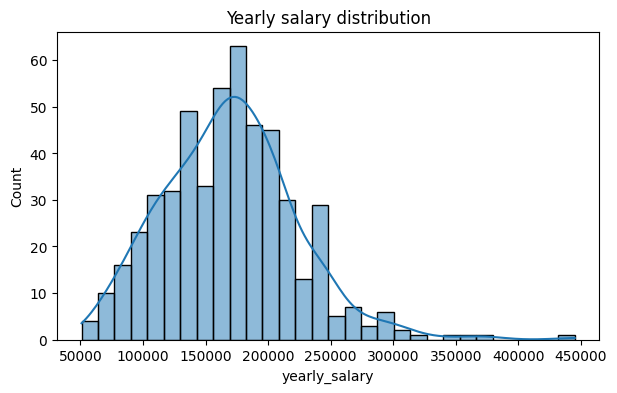

In [9]:
data = data[(data['yearly_salary'] > 20000) & (data['yearly_salary'] < 600000)]
print('Rows after cleaning:', len(data))

plt.figure(figsize=(7,4))
sns.histplot(data['yearly_salary'], bins=30, kde=True)
plt.title('Yearly salary distribution')
plt.show()

In [10]:
median_salary = data['yearly_salary'].median()
print('Median salary:', median_salary)

data['high_salary'] = (data['yearly_salary'] > median_salary).astype(int)
print(data['high_salary'].value_counts())

Median salary: 169150.0
high_salary
0    255
1    251
Name: count, dtype: int64


In [11]:
data['title'] = data['positionName'].str.lower()

data['is_senior'] = data['title'].str.contains('senior|sr\\.|sr |lead|principal|staff|manager|director').astype(int)

data['state'] = data['location'].str.extract(r',\s*([A-Z]{2})\b')[0].fillna('Other')
top_states = data['state'].value_counts().head(10).index
data['state'] = data['state'].where(data['state'].isin(top_states), 'Other')

data['job_type'] = data['jobType/0'].fillna('Unknown')

data[['title', 'rating', 'is_senior', 'state', 'job_type', 'yearly_salary', 'high_salary']].head()

,title,rating,is_senior,state,job_type,yearly_salary,high_salary
0,"senior data scientist, research, youtube search",4.3,1,CA,Full-time,205000.0,1
1,senior ai engineer - data scientist,3.7,1,Other,Full-time,133000.0,0
2,"audio software engineer, applied scientist",4.2,0,WA,Full-time,146993.6,0
3,"software engineer, machine learning",4.2,0,WA,Full-time,221795.0,1
5,"staff data scientist, research, search platforms",4.3,1,Other,Full-time,244000.0,1


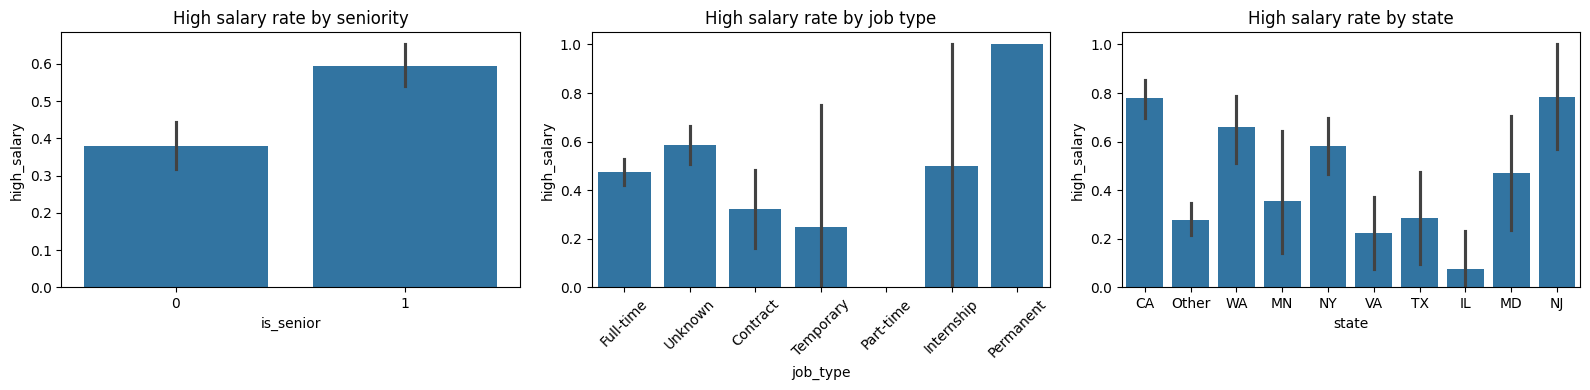

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16,4))
sns.barplot(data=data, x='is_senior', y='high_salary', ax=axes[0])
axes[0].set_title('High salary rate by seniority')
sns.barplot(data=data, x='job_type', y='high_salary', ax=axes[1])
axes[1].set_title('High salary rate by job type')
axes[1].tick_params(axis='x', rotation=45)
sns.barplot(data=data, x='state', y='high_salary', ax=axes[2])
axes[2].set_title('High salary rate by state')
plt.tight_layout()
plt.show()

In [13]:
structured = pd.concat([
    data[['rating', 'is_senior']],
    pd.get_dummies(data['job_type'], prefix='type'),
    pd.get_dummies(data['state'], prefix='state')
], axis=1).astype(float)

y = data['high_salary']
print('Structured features:', structured.shape)

Structured features: (506, 19)


## Task 3: Data Splitting
80% train, 20% test. TF-IDF is fitted on the training titles only.

In [14]:
X_train_s, X_test_s, y_train, y_test, title_train, title_test = train_test_split(
    structured, y, data['title'], test_size=0.2, random_state=42, stratify=y)

print('Training set:', X_train_s.shape)
print('Testing set :', X_test_s.shape)
print(y_train.value_counts().to_dict(), y_test.value_counts().to_dict())

Training set: (404, 19)
Testing set : (102, 19)
{0: 204, 1: 200} {0: 51, 1: 51}


In [15]:
tfidf = TfidfVectorizer(max_features=50, stop_words='english')
title_train_vec = tfidf.fit_transform(title_train).toarray()
title_test_vec = tfidf.transform(title_test).toarray()

X_train = np.hstack([X_train_s.values, title_train_vec])
X_test = np.hstack([X_test_s.values, title_test_vec])

feature_names = list(X_train_s.columns) + ['word_' + w for w in tfidf.get_feature_names_out()]
print('Final training matrix:', X_train.shape)

Final training matrix: (404, 69)


## Task 4: Model Training
Random Forest as the main model, Logistic Regression for comparison.

In [16]:
rf_model = RandomForestClassifier(n_estimators=200, random_state=42)
rf_model.fit(X_train, y_train)

lr_model = LogisticRegression(max_iter=2000, random_state=42)
lr_model.fit(X_train, y_train)

print('Both models trained.')

Both models trained.


## Task 5: Model Evaluation

In [17]:
labels = ['Low salary', 'High salary']

y_pred = rf_model.predict(X_test)

print('Random Forest')
print('Accuracy:', round(accuracy_score(y_test, y_pred), 4))
print()
print('Classification Report:')
print(classification_report(y_test, y_pred, target_names=labels))

Random Forest
Accuracy: 0.7157

Classification Report:
              precision    recall  f1-score   support

  Low salary       0.72      0.71      0.71        51
 High salary       0.71      0.73      0.72        51

    accuracy                           0.72       102
   macro avg       0.72      0.72      0.72       102
weighted avg       0.72      0.72      0.72       102



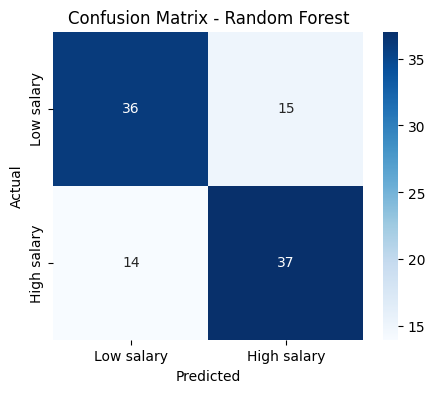

In [18]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Random Forest')
plt.show()

In [19]:
y_pred_lr = lr_model.predict(X_test)
print('Logistic Regression (baseline)')
print('Accuracy:', round(accuracy_score(y_test, y_pred_lr), 4))
print()
print(classification_report(y_test, y_pred_lr, target_names=labels))

Logistic Regression (baseline)
Accuracy: 0.7255

              precision    recall  f1-score   support

  Low salary       0.73      0.73      0.73        51
 High salary       0.73      0.73      0.73        51

    accuracy                           0.73       102
   macro avg       0.73      0.73      0.73       102
weighted avg       0.73      0.73      0.73       102



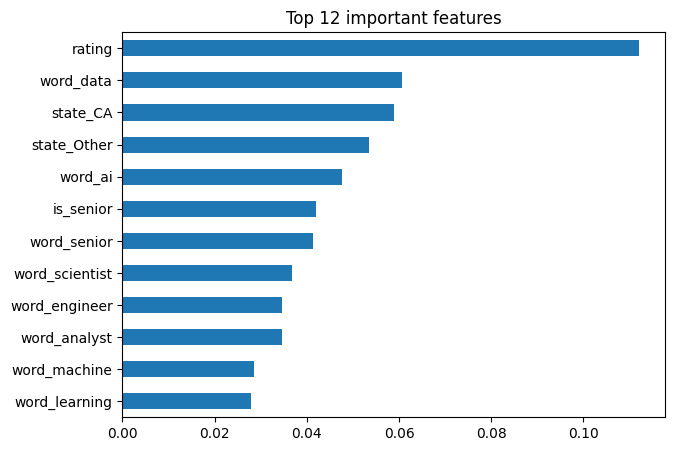

In [20]:
importance = pd.Series(rf_model.feature_importances_, index=feature_names).sort_values().tail(12)
importance.plot(kind='barh', figsize=(7,5), title='Top 12 important features')
plt.show()

## Conclusion
Random Forest got about **72% accuracy** (71.6%) on 102 test jobs, with precision, recall and F1 around 0.72 for both classes. Logistic Regression got almost the same (72.5%).

The model is better than random guessing (50%), so the title, location and job type do say something about the salary. It is not higher because salary also depends on experience, company and skills, which are not in the features.